In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cu130
GPU available: True


In [2]:
%pip install -q huggingface_hub

In [3]:

from pathlib import Path
from collections import Counter
from huggingface_hub import snapshot_download
from torchvision.datasets import ImageFolder

dataset_path = snapshot_download(
    repo_id="Sohaaam/Brain_Tumour_Curated",
    repo_type="dataset",
    allow_patterns=[
        "glioma/**",
        "meningioma/**",
        "no_tumor/**",
        "pituitary/**"
    ]
)

dataset_path = Path(dataset_path)
full_dataset = ImageFolder(root=str(dataset_path))

print("Total images:", len(full_dataset))
print("Class mapping:", full_dataset.class_to_idx)

counts = Counter(label for _, label in full_dataset.samples)
for name, index in full_dataset.class_to_idx.items():
    print(f"{name}: {counts[index]} images")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 40416 files:   0%|          | 0/40416 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import os

for class_name in sorted(os.listdir(DATA_DIR)):
    class_path = os.path.join(DATA_DIR, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff')
            )
        ]

        print(f"{class_name}: {len(images)} images")

In [ ]:

from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [ ]:

!pip -q install transformers

In [ ]:

from transformers import AutoImageProcessor

MODEL_NAME = "google/vit-base-patch16-224-in21k"

image_processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

print("Image size:", image_processor.size)
print("Image mean:", image_processor.image_mean)
print("Image std:", image_processor.image_std)
print("Rescale factor:", image_processor.rescale_factor)

In [ ]:

from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=image_processor.image_mean,
        std=image_processor.image_std
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=image_processor.image_mean,
        std=image_processor.image_std
    )
])

In [ ]:

from torchvision.datasets import ImageFolder
from collections import Counter

dataset = ImageFolder(DATA_DIR)

print("Class mapping:", dataset.class_to_idx)
print("Total images:", len(dataset))

counts = Counter(dataset.targets)

for class_idx, class_name in enumerate(dataset.classes):
    print(f"{class_name}: {counts[class_idx]} images")

In [ ]:

from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(dataset))
labels = np.array(dataset.targets)

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_idx]
)

print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Testing images:", len(test_idx))

In [ ]:

from torchvision.datasets import ImageFolder
from torch.utils.data import Subset

train_dataset = ImageFolder(
    DATA_DIR,
    transform=train_transform
)

eval_dataset = ImageFolder(
    DATA_DIR,
    transform=eval_transform
)

train_data = Subset(train_dataset, train_idx)
val_data = Subset(eval_dataset, val_idx)
test_data = Subset(eval_dataset, test_idx)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print("Class mapping:", train_dataset.class_to_idx)


In [ ]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel value range:",
      images.min().item(), "to", images.max().item())
print("Labels in this batch:", labels.tolist())
print("Class mapping:", train_dataset.class_to_idx)

In [ ]:

import torch
from transformers import ViTForImageClassification

MODEL_NAME = "google/vit-base-patch16-224-in21k"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

id2label = {
    0: "glioma",
    1: "meningioma",
    2: "no_tumor",
    3: "pituitary"
}

label2id = {name: idx for idx, name in id2label.items()}

model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

model = model.to(device)

print("Number of classes:", model.config.num_labels)
print("Model loaded on:", next(model.parameters()).device)

In [ ]:

model.train()

images, labels = next(iter(train_loader))
images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

optimizer.zero_grad(set_to_none=True)

outputs = model(pixel_values=images).logits
loss = criterion(outputs, labels)

loss.backward()

print("Logits shape:", outputs.shape)
print("Loss:", loss.item())
print("Classifier gradient exists:", model.classifier.weight.grad is not None)

optimizer.zero_grad(set_to_none=True)

In [ ]:

from torch.amp import autocast, GradScaler
from sklearn.metrics import accuracy_score, f1_score
import time

EPOCHS = 3

scaler = GradScaler("cuda")

print("Epochs:", EPOCHS)
print("Mixed precision: Enabled")
print("GPU:", torch.cuda.get_device_name(0))

In [ ]:

import os
import torch
import torchvision
from torch.utils.data import Subset, DataLoader
from torchvision.datasets import ImageFolder

print("=" * 65)
print("BRAIN TUMOR ViT - DIAGNOSTIC REPORT")
print("=" * 65)

# 1. Environment
print("\n[1] ENVIRONMENT")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Important variables
print("\n[2] IMPORTANT VARIABLES")
for name in [
    "MODEL_NAME", "EPOCHS", "BATCH_SIZE", "LR",
    "LEARNING_RATE", "NUM_CLASSES", "SAVE_PATH", "device"
]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

# 3. Model architecture
print("\n[3] MODEL")
if "model" in globals():
    print("Model type:", type(model))
    print("Model class:", model.__class__.__name__)
    print("Model config:", getattr(model, "config", "Not available"))
else:
    print("Model variable not found")

# 4. Dataset and transformations
def inspect_dataset(name, dataset):
    print(f"\n--- {name} ---")
    print("Type:", type(dataset).__name__)
    print("Length:", len(dataset))

    current = dataset
    depth = 0

    while isinstance(current, Subset):
        print(f"Subset layer {depth}: {len(current)} samples")
        print("First 10 indices:", list(current.indices[:10]))
        current = current.dataset
        depth += 1

    if hasattr(current, "root"):
        print("ImageFolder root:", current.root)

    if hasattr(current, "class_to_idx"):
        print("Classes:", current.class_to_idx)

    if hasattr(current, "transform"):
        print("Transform:", repr(current.transform))

    if hasattr(current, "target_transform"):
        print("Target transform:", repr(current.target_transform))

    return current

print("\n[4] DATASETS")
base_train = None
base_val = None

if "train_dataset" in globals():
    base_train = inspect_dataset("train_dataset", train_dataset)

if "val_loader" in globals():
    base_val = inspect_dataset(
        "val_loader.dataset", val_loader.dataset
    )

if "test_dataset" in globals():
    inspect_dataset("test_dataset", test_dataset)

# 5. DataLoaders
print("\n[5] DATALOADERS")
for name in ["train_loader", "val_loader", "test_loader"]:
    if name in globals():
        loader = globals()[name]
        print(f"\n{name}:")
        print("Dataset size:", len(loader.dataset))
        print("Batch size:", loader.batch_size)
        print("Number of batches:", len(loader))
        print("Drop last:", loader.drop_last)
        print("Workers:", loader.num_workers)
        print("Pinned memory:", loader.pin_memory)

# 6. Split overlap
print("\n[6] SPLIT OVERLAP CHECK")
if (
    "train_loader" in globals()
    and "val_loader" in globals()
    and isinstance(train_loader.dataset, Subset)
    and isinstance(val_loader.dataset, Subset)
):
    train_ds = train_loader.dataset
    val_ds = val_loader.dataset

    if train_ds.dataset is val_ds.dataset:
        tr = set(train_ds.indices)
        va = set(val_ds.indices)
        print("Same underlying dataset: YES")
        print("Train/validation overlap:", len(tr & va))
        print("Unused indices:", len(set(range(len(train_ds.dataset))) - tr - va))
    else:
        print("Training and validation use different underlying objects.")
else:
    print("Could not directly compare split indices.")

# 7. Optimizer and loss
print("\n[7] TRAINING CONFIGURATION")
if "optimizer" in globals():
    print("Optimizer:", optimizer.__class__.__name__)
    print("Optimizer settings:", optimizer.defaults)

if "criterion" in globals():
    print("Loss function:", repr(criterion))

if "scaler" in globals():
    print("AMP scaler:", type(scaler).__name__)

# 8. Saved checkpoint
print("\n[8] CHECKPOINT")
checkpoint_path = globals().get(
    "SAVE_PATH",
    "/content/drive/MyDrive/vit_brain_tumor_best.pth"
)
print("Path:", checkpoint_path)
print("Exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Size (MB):", round(
        os.path.getsize(checkpoint_path) / (1024**2), 2
    ))

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )
        if isinstance(checkpoint, dict):
            print("Checkpoint keys:", list(checkpoint.keys()))
            for key in [
                "epoch", "val_f1", "val_accuracy",
                "class_to_idx", "model_name"
            ]:
                if key in checkpoint:
                    print(f"{key}: {checkpoint[key]}")
        del checkpoint
    except Exception as e:
        print("Checkpoint inspection message:", str(e)[:300])

# 9. Sample batch shape
print("\n[9] SAMPLE BATCH")
for name in ["train_loader", "val_loader"]:
    if name in globals():
        try:
            images, labels = next(iter(globals()[name]))
            print(name, "image shape:", tuple(images.shape))
            print(name, "label shape:", tuple(labels.shape))
            print(name, "image dtype:", images.dtype)
            print(name, "pixel range:",
                  images.min().item(), images.max().item())
            break
        except Exception as e:
            print(name, "could not inspect:", str(e)[:200])

print("\n" + "=" * 65)
print("END OF DIAGNOSTIC REPORT")
print("=" * 65)


BRAIN TUMOR ViT - DIAGNOSTIC REPORT

[1] ENVIRONMENT
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4

[2] IMPORTANT VARIABLES
MODEL_NAME: google/vit-base-patch16-224-in21k
EPOCHS: 3
BATCH_SIZE: 16
SAVE_PATH: /content/drive/MyDrive/vit_brain_tumor_best.pth
device: cuda

[3] MODEL
Model type: <class 'transformers.models.vit.modeling_vit.ViTForImageClassification'>
Model class: ViTForImageClassification
Model config: ViTConfig {
  "architectures": [
    "ViTModel"
  ],
  "attention_probs_dropout_prob": 0.0,
  "dtype": "float32",
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "id2label": {
    "0": "glioma",
    "1": "meningioma",
    "2": "no_tumor",
    "3": "pituitary"
  },
  "image_size": 224,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "label2id": {
    "glioma": 0,
    "meningioma": 1,
    "no_tumor": 2,
    "pituitary": 3
  },
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  

In [ ]:

from torch.utils.data import Subset

def unwrap_dataset(ds):
    indices = None
    while isinstance(ds, Subset):
        current = list(ds.indices)
        if indices is None:
            indices = current
        else:
            indices = [current[i] for i in indices]
        ds = ds.dataset
    return ds, indices

def get_paths(ds, indices):
    base, subset_indices = unwrap_dataset(ds)

    if not hasattr(base, "samples"):
        raise TypeError("Underlying dataset has no ImageFolder samples")

    if subset_indices is None:
        selected = range(len(base.samples))
    else:
        selected = subset_indices

    return {
        os.path.realpath(base.samples[i][0])
        for i in selected
    }

train_paths = get_paths(train_loader.dataset, None)
val_paths = get_paths(val_loader.dataset, None)
test_paths = get_paths(test_loader.dataset, None)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))

print("Train ∩ Validation:", len(train_paths & val_paths))
print("Train ∩ Test:", len(train_paths & test_paths))
print("Validation ∩ Test:", len(val_paths & test_paths))


Training images: 32336
Validation images: 4042
Test images: 4042
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [ ]:

import torch

checkpoint = torch.load(
    "/content/drive/MyDrive/vit_brain_tumor_best.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Validation macro-F1:", round(checkpoint["val_f1"], 4))
print("Class mapping:", checkpoint["class_to_idx"])


Checkpoint loaded successfully!
Best epoch: 3
Validation macro-F1: 0.9113
Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


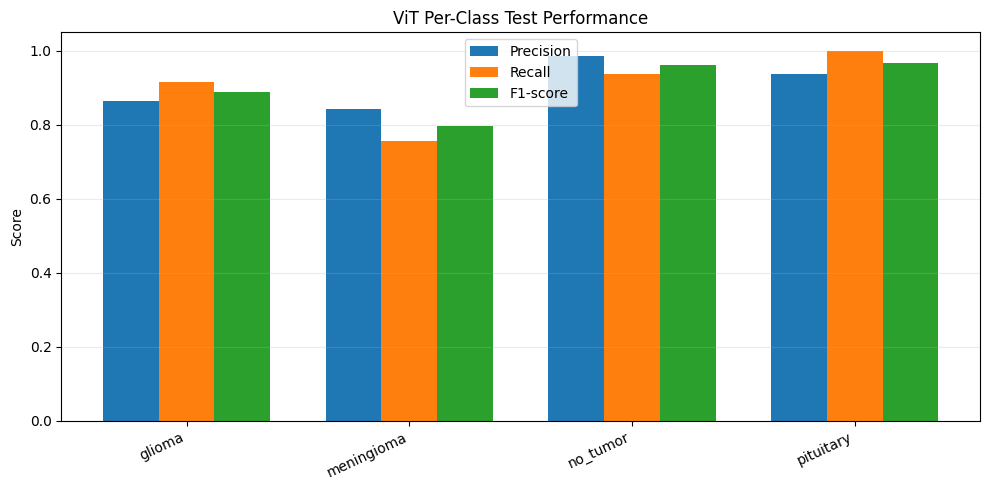

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    zero_division=0
)

x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, f1, width, label="F1-score")

ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=25, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("ViT Per-Class Test Performance")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

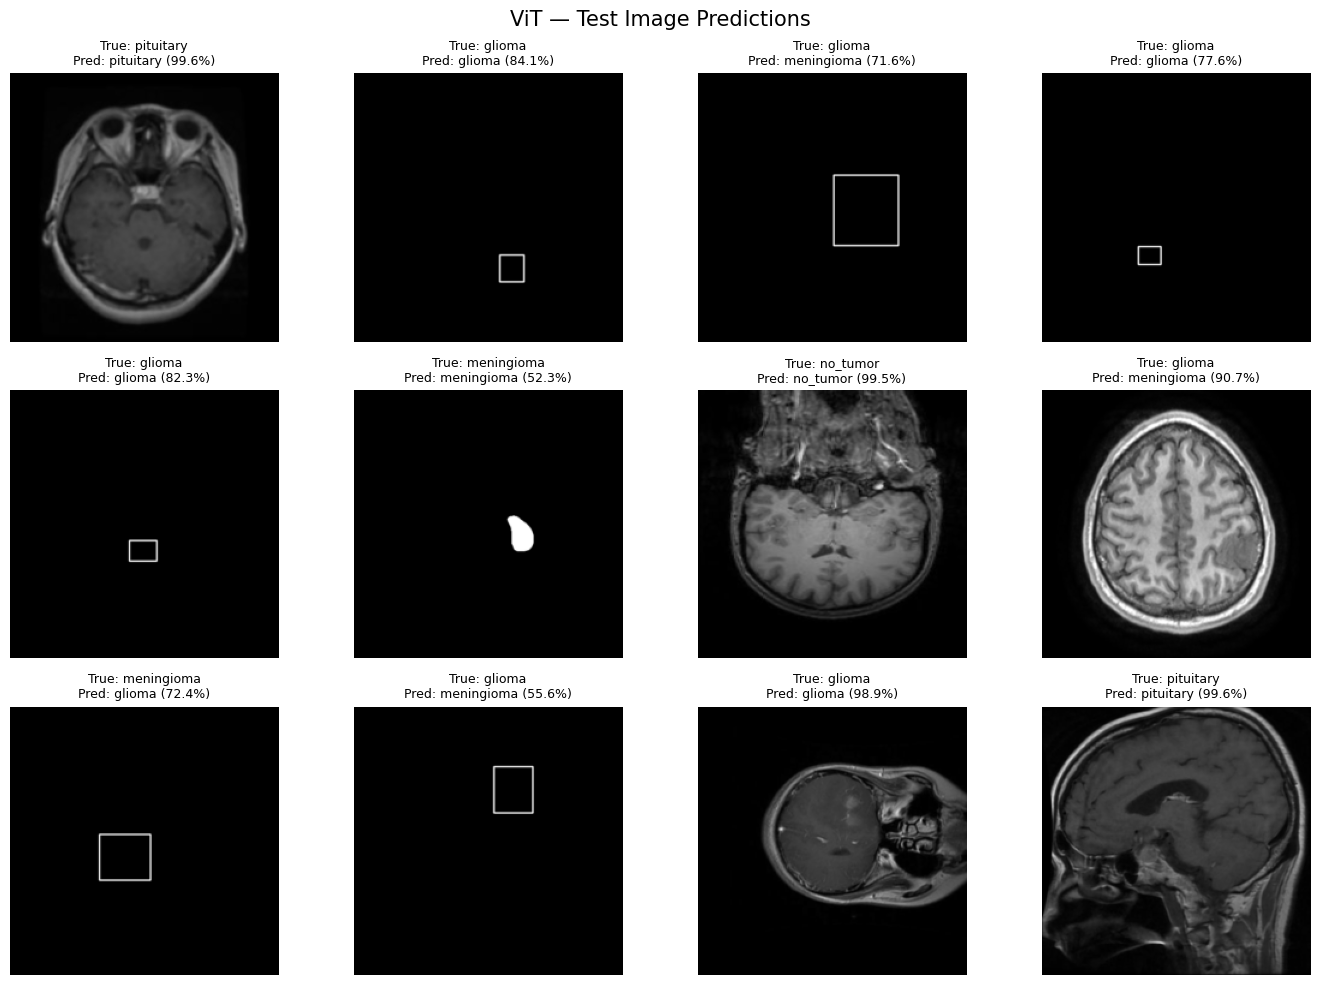

In [ ]:
import torch
import matplotlib.pyplot as plt
from torch.amp import autocast

model.eval()
images, labels = next(iter(test_loader))
images = images.to(device)

with torch.inference_mode():
    with autocast("cuda", dtype=torch.float16):
        logits = model(pixel_values=images).logits

    probs = torch.softmax(logits.float(), dim=1)
    confidences, preds = probs.max(dim=1)

images = images.cpu()
labels = labels.cpu()
preds = preds.cpu()
confidences = confidences.cpu()

n = min(12, len(labels))
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i >= n:
        ax.axis("off")
        continue

    # Undo normalization: mean=0.5, std=0.5
    img = (images[i] * 0.5 + 0.5).clamp(0, 1)
    img = img.permute(1, 2, 0).numpy()

    true_name = class_names[labels[i].item()]
    pred_name = class_names[preds[i].item()]
    confidence = confidences[i].item() * 100

    ax.imshow(img)
    ax.set_title(
        f"True: {true_name}\n"
        f"Pred: {pred_name} ({confidence:.1f}%)",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("ViT — Test Image Predictions", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
import os

OUTPUT_DIR = "/content/drive/MyDrive/🤯🤯🤯/vit_bt_model"
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")

os.makedirs(FIGURE_DIR, exist_ok=True)

print("Output folder:", OUTPUT_DIR)
print("Figures folder:", FIGURE_DIR)

Output folder: /content/drive/MyDrive/🤯🤯🤯/vit_bt_model
Figures folder: /content/drive/MyDrive/🤯🤯🤯/vit_bt_model/figures


Checkpoint saved.


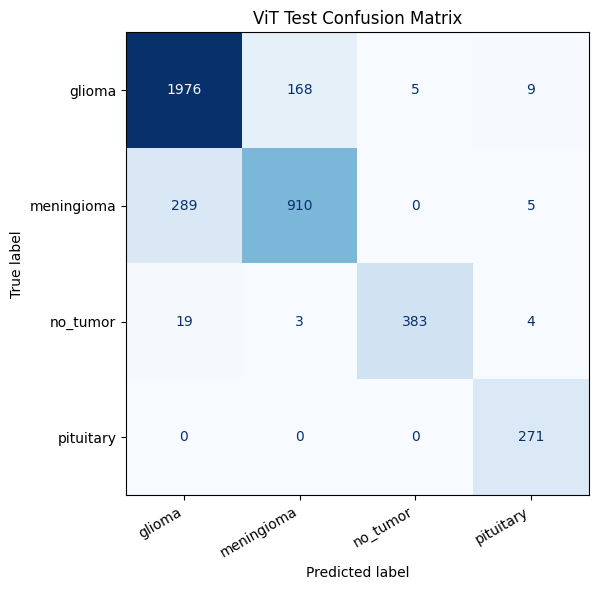

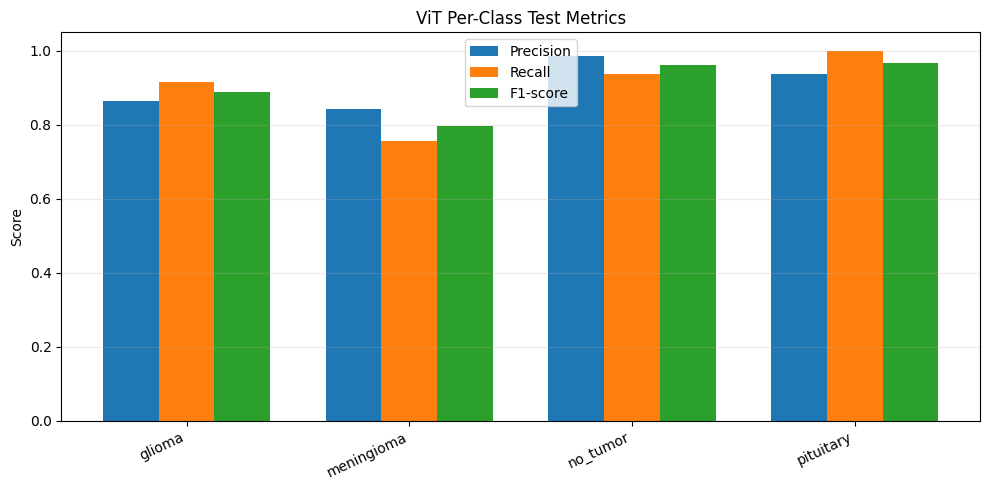


===== VIТ RESULTS =====
Test accuracy: 87.58%
Test macro-F1: 0.9038
Test loss: 0.2442

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      glioma     0.8651    0.9157    0.8897      2158
  meningioma     0.8418    0.7558    0.7965      1204
    no_tumor     0.9871    0.9364    0.9611       409
   pituitary     0.9377    1.0000    0.9679       271

    accuracy                         0.8758      4042
   macro avg     0.9079    0.9020    0.9038      4042
weighted avg     0.8754    0.8758    0.8744      4042


===== SAVED FILES =====
confusion_matrix.csv (0.00 MB)
test_predictions.csv (0.09 MB)
vit_brain_tumor_best.pth (982.16 MB)
vit_classification_report.txt (0.00 MB)
vit_test_results.json (0.00 MB)
figures/class_metrics.png (0.10 MB)
figures/confusion_matrix.png (0.12 MB)


In [ ]:
import os
import json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)

# 1. Save a copy of the trained model checkpoint
checkpoint_src = "/content/drive/MyDrive/vit_brain_tumor_best.pth"
checkpoint_dst = os.path.join(OUTPUT_DIR, "vit_brain_tumor_best.pth")

if os.path.exists(checkpoint_src):
    import shutil
    shutil.copy2(checkpoint_src, checkpoint_dst)
    print("Checkpoint saved.")
else:
    print("Checkpoint source not found; keeping your original checkpoint.")

# 2. Save overall test metrics
results = {
    "model": MODEL_NAME,
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_images": int(len(all_labels)),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_acc),
    "test_macro_f1": float(test_f1),
    "class_to_idx": checkpoint["class_to_idx"]
}

with open(os.path.join(OUTPUT_DIR, "vit_test_results.json"), "w") as f:
    json.dump(results, f, indent=4)

# 3. Save detailed per-class report
report = classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

with open(os.path.join(OUTPUT_DIR, "vit_classification_report.txt"), "w") as f:
    f.write(report)

# 4. Save confusion matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("ViT Test Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURE_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 5. Save precision, recall and F1 chart
precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    zero_division=0
)

import numpy as np

x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width, precision, width, label="Precision")
ax.bar(x, recall, width, label="Recall")
ax.bar(x + width, f1, width, label="F1-score")

ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=25, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("ViT Per-Class Test Metrics")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURE_DIR, "class_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 6. Save test predictions
prediction_df = pd.DataFrame({
    "actual_class": [class_names[i] for i in all_labels],
    "predicted_class": [class_names[i] for i in all_preds],
    "correct": [a == p for a, p in zip(all_labels, all_preds)]
})

prediction_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# 7. Save a copy of the test confusion-matrix values
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(os.path.join(OUTPUT_DIR, "confusion_matrix.csv"))

# 8. Save a summary
print("\n===== VIТ RESULTS =====")
print(f"Test accuracy: {test_acc:.2%}")
print(f"Test macro-F1: {test_f1:.4f}")
print(f"Test loss: {test_loss:.4f}")
print("\n===== CLASSIFICATION REPORT =====")
print(report)

print("\n===== SAVED FILES =====")
for root, dirs, files in os.walk(OUTPUT_DIR):
    for filename in sorted(files):
        path = os.path.join(root, filename)
        print(os.path.relpath(path, OUTPUT_DIR),
              f"({os.path.getsize(path) / (1024**2):.2f} MB)")